In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

In [2]:
data = load_breast_cancer()

X = pd.DataFrame(data.data, columns=data.feature_names)

y = data.target

print("Dataset loaded successfully!")
print("Total Rows:", X.shape[0])
print("Total Features:", X.shape[1])

Dataset loaded successfully!
Total Rows: 569
Total Features: 30


In [3]:
df = X.copy()

df["target"] = y

df.head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoothness error         5

In [5]:
df.describe()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
count,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,0.062798,...,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946,0.627417
std,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,0.007060,...,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061,0.483918
min,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,0.049960,...,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040,0.000000
25%,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,0.057700,...,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460,0.000000
50%,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,0.061540,...,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040,1.000000
75%,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,0.066120,...,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080,1.000000
max,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,0.097440,...,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500,1.000000


In [6]:
print("Target Distribution:")
print(df["target"].value_counts())

print("\nTarget Names:")
print(data.target_names)

Target Distribution:
target
1    357
0    212
Name: count, dtype: int64

Target Names:
['malignant' 'benign']


In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (455, 30)
Testing Data: (114, 30)


In [8]:
pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=2000))
])

In [9]:
baseline_model = pipeline.fit(X_train, y_train)

baseline_predictions = baseline_model.predict(X_test)

print("Baseline model trained successfully!")

Baseline model trained successfully!


In [10]:
baseline_accuracy = accuracy_score(y_test, baseline_predictions)

baseline_precision = precision_score(
    y_test, baseline_predictions, pos_label=0
)

baseline_recall = recall_score(
    y_test, baseline_predictions, pos_label=0
)

baseline_f1 = f1_score(
    y_test, baseline_predictions, pos_label=0
)

print("Baseline Model Results")
print("----------------------")
print("Accuracy:", baseline_accuracy)
print("Precision:", baseline_precision)
print("Recall:", baseline_recall)
print("F1 Score:", baseline_f1)

Baseline Model Results
----------------------
Accuracy: 0.9824561403508771
Precision: 0.9761904761904762
Recall: 0.9761904761904762
F1 Score: 0.9761904761904762


In [11]:
print(classification_report(
    y_test,
    baseline_predictions,
    labels=[0, 1],
    target_names=["Malignant", "Benign"]
))

              precision    recall  f1-score   support

   Malignant       0.98      0.98      0.98        42
      Benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



In [12]:
parameters = {
    "model__C": [0.01, 0.1, 1, 10, 100],
    "model__solver": ["liblinear", "lbfgs"]
}

grid_search = GridSearchCV(
    pipeline,
    parameters,
    cv=5,
    scoring="accuracy"
)

grid_search.fit(X_train, y_train)

GridSearchCV(cv=5,
             estimator=Pipeline(steps=[('scaler', StandardScaler()),
                                       ('model',
                                        LogisticRegression(max_iter=2000))]),
             param_grid={'model__C': [0.01, 0.1, 1, 10, 100],
                         'model__solver': ['liblinear', 'lbfgs']},
             scoring='accuracy')

In [13]:
print("Best Parameters:")
print(grid_search.best_params_)

print("\nBest Cross Validation Score:")
print(grid_search.best_score_)

Best Parameters:
{'model__C': 0.1, 'model__solver': 'liblinear'}

Best Cross Validation Score:
0.9802197802197803


In [14]:
tuned_model = grid_search.best_estimator_

tuned_predictions = tuned_model.predict(X_test)

print("Tuned model predictions completed!")

Tuned model predictions completed!


In [15]:
tuned_accuracy = accuracy_score(y_test, tuned_predictions)

tuned_precision = precision_score(
    y_test, tuned_predictions, pos_label=0
)

tuned_recall = recall_score(
    y_test, tuned_predictions, pos_label=0
)

tuned_f1 = f1_score(
    y_test, tuned_predictions, pos_label=0
)

print("Tuned Model Results")
print("-------------------")
print("Accuracy:", tuned_accuracy)
print("Precision:", tuned_precision)
print("Recall:", tuned_recall)
print("F1 Score:", tuned_f1)

Tuned Model Results
-------------------
Accuracy: 0.9824561403508771
Precision: 0.9761904761904762
Recall: 0.9761904761904762
F1 Score: 0.9761904761904762


In [16]:

print(classification_report(
    y_test,
    tuned_predictions,
    labels=[0, 1],
    target_names=["Malignant", "Benign"]
))

              precision    recall  f1-score   support

   Malignant       0.98      0.98      0.98        42
      Benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



In [17]:
comparison = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1 Score"],
    "Baseline Model": [
        baseline_accuracy,
        baseline_precision,
        baseline_recall,
        baseline_f1
    ],
    "Tuned Model": [
        tuned_accuracy,
        tuned_precision,
        tuned_recall,
        tuned_f1
    ]
})

print(comparison)

      Metric  Baseline Model  Tuned Model
0   Accuracy        0.982456     0.982456
1  Precision        0.976190     0.976190
2     Recall        0.976190     0.976190
3   F1 Score        0.976190     0.976190


In [18]:
if tuned_accuracy > baseline_accuracy:
    print("Tuned model performed better.")

elif tuned_accuracy < baseline_accuracy:
    print("Baseline model performed better.")

else:
    print("Both models performed equally.")

Both models performed equally.


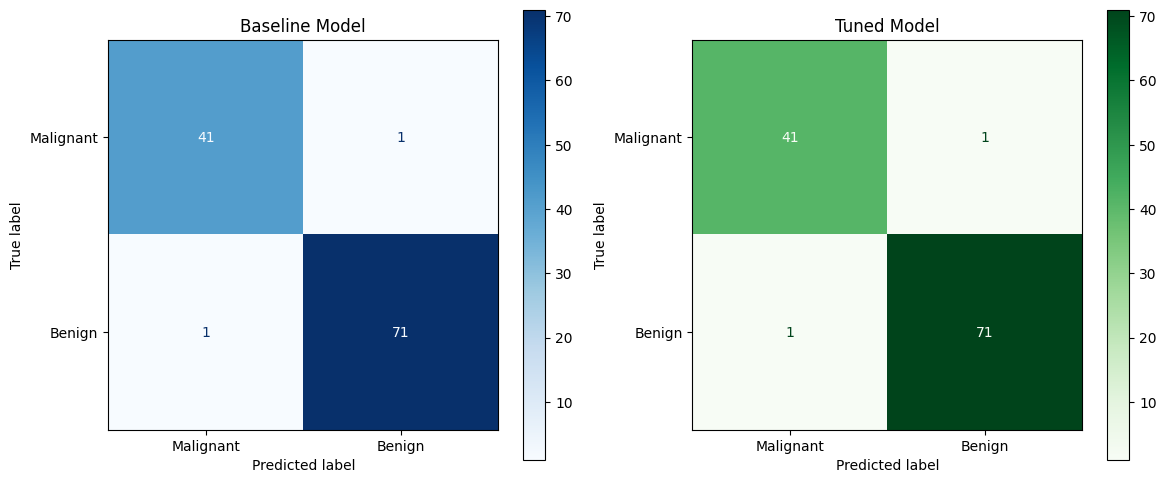

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    baseline_predictions,
    labels=[0, 1],
    display_labels=["Malignant", "Benign"],
    cmap="Blues",
    ax=axes[0]
)

axes[0].set_title("Baseline Model")

ConfusionMatrixDisplay.from_predictions(
    y_test,
    tuned_predictions,
    labels=[0, 1],
    display_labels=["Malignant", "Benign"],
    cmap="Greens",
    ax=axes[1]
)

axes[1].set_title("Tuned Model")

plt.tight_layout()
plt.show()

In [20]:
print("BREAST CANCER PREDICTION SYSTEM")
print("--------------------------------")

print("Dataset: Breast Cancer Wisconsin")
print("Algorithm: Logistic Regression")

print("\nBest Parameters:")
print(grid_search.best_params_)

print("\nBaseline Accuracy:", baseline_accuracy)
print("Tuned Accuracy:", tuned_accuracy)

print("\nBaseline F1 Score:", baseline_f1)
print("Tuned F1 Score:", tuned_f1)

print("\nProject Completed Successfully!")

BREAST CANCER PREDICTION SYSTEM
--------------------------------
Dataset: Breast Cancer Wisconsin
Algorithm: Logistic Regression

Best Parameters:
{'model__C': 0.1, 'model__solver': 'liblinear'}

Baseline Accuracy: 0.9824561403508771
Tuned Accuracy: 0.9824561403508771

Baseline F1 Score: 0.9761904761904762
Tuned F1 Score: 0.9761904761904762

Project Completed Successfully!
